# Fase 3 — Auditoría y comunicación
**Proyecto Integrador · Deep Learning · Universidad Externado de Colombia**  
**Autor:** Nelson Andrey García Patarroyo  
**Modelo:** RoBERTa-BNE (encoder congelado) + cabeza entrenable

Este cuaderno (1) consolida el modelo final, (2) lo audita con explicabilidad (saliencia por gradiente × entrada y atención),
pruebas de atajos, casos de respuesta conocida y calibración, y (3) caracteriza las fallas. Tarda pocos minutos en una GPU T4.

**Cómo correrlo:** Entorno de ejecución → GPU T4 → Ejecutar todas las celdas. Cuando lo pida, sube `fake_news_dataset.csv`.
Al final se descarga `resultados_fase3.zip`; sus archivos están en `resultados/fase3/` del repositorio.

In [1]:
# Celda 1 — Configuración e importaciones
import os, sys, json, re, time, random, warnings, shutil, unicodedata
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt
import transformers, sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef,
                             roc_auc_score, brier_score_loss, confusion_matrix)
from scipy.stats import spearmanr

MODEL_ID = os.environ.get("MODEL_ID_OVERRIDE", "IsGarrido/roberta-base-bne")   # copia comunitaria verificada (los pesos de PlanTL fueron retirados)
FALLBACK = "Buzzeitor/roberta-base-bne"
SEED_COL, MAX_LEN, BATCH, WEIGHT_DECAY, DROPOUT = 42, 128, 16, 0.001, 0.15
GRID = [dict(epochs=e, lr=l) for e in (10, 30, 60) for l in (3e-4, 1e-3)]        # cuadrícula del cabezal (se elige SOLO con validación cruzada)
CV_SEEDS, FINAL_SEEDS, N_BOOT = [0, 1, 2], list(range(10)), 2000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("resultados_fase3"); OUT.mkdir(exist_ok=True)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#6b6b6b"
T0 = time.time()
ENV = dict(torch=torch.__version__, transformers=transformers.__version__, sklearn=sklearn.__version__, device=DEVICE,
           gpu=(torch.cuda.get_device_name(0) if DEVICE == "cuda" else None))
print(ENV)
if DEVICE == "cpu" and not os.environ.get("MODEL_ID_OVERRIDE"):
    print("ATENCIÓN: sin GPU. Activa una GPU en Colab (Entorno de ejecución → Cambiar tipo).")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if DEVICE == "cuda": torch.cuda.manual_seed_all(s)

def get_file(desc, default):
    p = Path(default)
    if p.exists(): return p
    try:
        from google.colab import files
        print("Sube", desc); up = files.upload()
        if not up: raise FileNotFoundError("No se subió ningún archivo.")
        return Path(next(iter(up)))
    except ImportError:
        raise FileNotFoundError(f"No encuentro {default}. Colócalo junto al cuaderno.")

{'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'sklearn': '1.6.1', 'device': 'cuda', 'gpu': 'Tesla T4'}


In [2]:
# Celda 2 — Datos, partición idéntica a las Fases 1 y 2 y línea base
def read_csv_robust(path):
    last = None
    for enc in ["utf-8-sig", "utf-8", "latin-1"]:
        for sep in [";", ",", "\t"]:
            try:
                d = pd.read_csv(path, sep=sep, encoding=enc)
                d.columns = [str(c).replace("﻿", "").strip() for c in d.columns]
                if {"titulo", "texto", "fake_news"} <= set(d.columns):
                    return d.loc[:, ~pd.Index(d.columns).str.match(r"^Unnamed")]
            except Exception as e: last = e
    raise ValueError(f"No pude leer el CSV con columnas titulo/texto/fake_news. Último error: {last}")

df = read_csv_robust(get_file("fake_news_dataset.csv", os.environ.get("COL_CSV", "fake_news_dataset.csv")))
df["y"] = df["fake_news"].astype(str).str.strip().str.lower().eq("true").astype(int)      # 1 = verdadera, 0 = falsa
for c in ["fuente", "medio", "clasificacion", "audiovisual"]:
    df[c] = df[c].astype(str).str.strip() if c in df.columns else "?"
df["text_raw"] = df["titulo"].fillna("").astype(str) + " " + df["texto"].fillna("").astype(str)   # ÚNICA entrada del modelo
def clean_text(t):
    t = re.sub(r"http\S+|www\.\S+", " ", str(t).lower()); t = re.sub(r"[^a-záéíóúñü0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()
df["text_clean"] = df.text_raw.apply(clean_text)
y_all = df.y.values; idx_all = np.arange(len(df))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.2, stratify=y_all, random_state=SEED_COL)
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED_COL).split(tr_idx, y_all[tr_idx]))
print(f"n={len(df)} | verdaderas={int(y_all.sum())} | desarrollo={len(tr_idx)} | prueba={len(te_idx)}")
if not (len(df) == 134 and len(tr_idx) == 107 and len(te_idx) == 27):
    print("⚠ ADVERTENCIA: el tamaño no coincide con 134/107/27 de las Fases 1-2; ¿subiste el CSV correcto?")
y_tr, y_te = y_all[tr_idx], y_all[te_idx]

def make_baseline():
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED_COL))])
Xc = df.text_clean.values
base_oof = np.zeros(len(tr_idx))
for a, b in folds:
    base_oof[b] = make_baseline().fit(Xc[tr_idx[a]], y_tr[a]).predict_proba(Xc[tr_idx[b]])[:, 1]
t0 = time.perf_counter(); base = make_baseline().fit(Xc[tr_idx], y_tr); t_base_fit = time.perf_counter() - t0
t0 = time.perf_counter(); base_te = base.predict_proba(Xc[te_idx])[:, 1]; t_base_pred = (time.perf_counter() - t0) / len(te_idx)
print("Línea base — F1 prueba @0.5:", round(f1_score(y_te, base_te >= .5), 3), "(Fase 1: 0.455)")

Sube fake_news_dataset.csv


Saving fake_news_dataset.csv to fake_news_dataset.csv
n=134 | verdaderas=60 | desarrollo=107 | prueba=27
Línea base — F1 prueba @0.5: 0.455 (Fase 1: 0.455)


In [3]:
# Celda 3 — Codificador congelado: se calcula UNA vez el vector [CLS] de cada texto
from transformers import AutoTokenizer, AutoModel
def load_encoder():
    cands = [MODEL_ID] if os.environ.get("MODEL_ID_OVERRIDE") else [MODEL_ID, FALLBACK]
    for c in cands:
        try:
            tk = AutoTokenizer.from_pretrained(c)
            m = AutoModel.from_pretrained(c, attn_implementation="eager")     # "eager" para poder leer las matrices de atención
            return c, tk, m
        except Exception as e:
            print(f"No pude cargar {c}: {type(e).__name__}: {str(e)[:150]}")
    raise RuntimeError("No se pudo descargar RoBERTa-BNE. Revisa Internet en Colab.")
MODEL_ID, tok, enc = load_encoder()
enc = enc.to(DEVICE).eval()
for p in enc.parameters(): p.requires_grad = False
print("Modelo:", MODEL_ID, "| parámetros del encoder:", sum(p.numel() for p in enc.parameters()))

@torch.no_grad()
def embed(texts, bs=16):
    out = []
    for i in range(0, len(texts), bs):
        b = tok([str(t) for t in texts[i:i + bs]], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
        out.append(enc(**b).last_hidden_state[:, 0, :].float().cpu())
    return torch.cat(out).numpy()
t0 = time.perf_counter(); X_all = embed(df.text_raw.values); t_embed = (time.perf_counter() - t0) / len(df)
X_tr, X_te = X_all[tr_idx], X_all[te_idx]
print("Embeddings:", X_all.shape, f"| {t_embed*1000:.1f} ms por texto en {DEVICE}")

[transformers] RobertaModel LOAD REPORT from: IsGarrido/roberta-base-bne
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.decoder.weight    | UNEXPECTED | 
lm_head.decoder.bias      | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo: IsGarrido/roberta-base-bne | parámetros del encoder: 124643328


Embeddings: (134, 768) | 12.2 ms por texto en cuda


In [4]:
# Celda 4 — Cabezal entrenable y métricas
class Head(nn.Module):                                   # igual que la cabeza de RobertaForSequenceClassification
    def __init__(s, d=768, p=DROPOUT):
        super().__init__(); s.drop = nn.Dropout(p); s.dense = nn.Linear(d, d); s.out = nn.Linear(d, 2)
    def forward(s, x): return s.out(s.drop(torch.tanh(s.dense(s.drop(x)))))

def train_head(X, y, epochs, lr, seed):
    set_seed(seed); sc = StandardScaler().fit(X)
    Xt = torch.tensor(sc.transform(X), dtype=torch.float); yt = torch.tensor(np.asarray(y))
    cnt = np.bincount(y, minlength=2); w = torch.tensor(len(y) / (2.0 * cnt), dtype=torch.float)      # ponderación 'balanced'
    h = Head(X.shape[1]); opt = torch.optim.AdamW(h.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    lossf = nn.CrossEntropyLoss(weight=w); g = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        h.train(); perm = torch.randperm(len(y), generator=g)
        for i in range(0, len(y), BATCH):
            j = perm[i:i + BATCH]; opt.zero_grad(); lossf(h(Xt[j]), yt[j]).backward()
            nn.utils.clip_grad_norm_(h.parameters(), 1.0); opt.step()
    h.eval(); return dict(head=h, sc=sc)

def head_proba(m, X):
    with torch.no_grad():
        return torch.softmax(m["head"](torch.tensor(m["sc"].transform(X), dtype=torch.float)), -1)[:, 1].numpy()

def ece(y, p, bins=5):
    e = np.linspace(0, 1, bins + 1); tot = 0.0
    for i in range(bins):
        m = (p >= e[i]) & ((p < e[i + 1]) if i < bins - 1 else (p <= e[i + 1]))
        if m.any(): tot += m.mean() * abs(np.mean(y[m]) - np.mean(p[m]))
    return float(tot)

def metr(y, p, thr=0.5):
    y = np.asarray(y); pr = (np.asarray(p) >= thr).astype(int)
    return dict(accuracy=float(accuracy_score(y, pr)), precision=float(precision_score(y, pr, zero_division=0)),
                recall=float(recall_score(y, pr, zero_division=0)), f1=float(f1_score(y, pr, zero_division=0)),
                mcc=float(matthews_corrcoef(y, pr)), auc=float(roc_auc_score(y, p)) if len(set(y)) > 1 else float("nan"),
                brier=float(brier_score_loss(y, p)), ece=ece(y, np.asarray(p)), prop_pred_verdadera=float(pr.mean()),
                cm=confusion_matrix(y, pr, labels=[0, 1]).tolist())

def best_thr(y, p):                                      # umbral que maximiza el MCC en las predicciones fuera de muestra (sin usar la prueba)
    ts = np.linspace(0.2, 0.8, 61); m = np.array([matthews_corrcoef(y, (p >= t).astype(int)) for t in ts])
    return float(np.median(ts[m >= m.max() - 1e-9]))

In [5]:
# Celda 5 — Selección del modelo final SOLO con validación cruzada (107 casos de desarrollo)
def cv_oof(cfg, seeds=CV_SEEDS, keep=False):
    oof = np.zeros(len(tr_idx)); store = {}
    for k, (a, b) in enumerate(folds):
        ms = [train_head(X_tr[a], y_tr[a], cfg["epochs"], cfg["lr"], s) for s in seeds]
        oof[b] = np.mean([head_proba(m, X_tr[b]) for m in ms], 0)
        if keep: store[k] = ms
    return (oof, store) if keep else oof

t0 = time.perf_counter(); rows, oofs = [], {}
for i, cfg in enumerate(GRID):
    o = cv_oof(cfg); oofs[i] = o; mm = metr(y_tr, o)
    rows.append(dict(cfg=f"ep{cfg['epochs']}_lr{cfg['lr']:g}", **{k: round(mm[k], 3) for k in ["auc", "mcc", "f1", "accuracy"]}))
grid_table = pd.DataFrame(rows); print(grid_table.to_string(index=False))
t_cv = time.perf_counter() - t0
best_i = int(np.argmax([roc_auc_score(y_tr, oofs[i]) for i in range(len(GRID))])); BEST = GRID[best_i]
print("Configuración elegida por AUC en CV:", BEST)
oof_t, fold_heads = cv_oof(BEST, keep=True)
thr_t, thr_b = best_thr(y_tr, oof_t), best_thr(y_tr, base_oof)
print(f"Umbral elegido por CV → Transformer {thr_t:.2f} | línea base {thr_b:.2f}")

# referencia: regresión logística sobre los mismos embeddings congelados
lr_oof = np.zeros(len(tr_idx))
for a, b in folds:
    sc = StandardScaler().fit(X_tr[a]); lr_oof[b] = LogisticRegression(C=0.01, class_weight="balanced", max_iter=2000).fit(sc.transform(X_tr[a]), y_tr[a]).predict_proba(sc.transform(X_tr[b]))[:, 1]

          cfg   auc   mcc    f1  accuracy
ep10_lr0.0003 0.695 0.238 0.602     0.617
 ep10_lr0.001 0.697 0.288 0.620     0.645
ep30_lr0.0003 0.696 0.268 0.606     0.636
 ep30_lr0.001 0.704 0.288 0.620     0.645
ep60_lr0.0003 0.697 0.272 0.614     0.636
 ep60_lr0.001 0.695 0.288 0.620     0.645
Configuración elegida por AUC en CV: {'epochs': 30, 'lr': 0.001}
Umbral elegido por CV → Transformer 0.24 | línea base 0.51


In [6]:
# Celda 6 — Modelo final (10 semillas), prueba única y comparación contra la línea base
t0 = time.perf_counter(); final_heads = [train_head(X_tr, y_tr, BEST["epochs"], BEST["lr"], s) for s in FINAL_SEEDS]; t_head_fit = (time.perf_counter() - t0) / len(FINAL_SEEDS)
te_seed = np.array([head_proba(m, X_te) for m in final_heads]); te_ens = te_seed.mean(0)
per_seed = [metr(y_te, p, thr_t) for p in te_seed]
sd = lambda k: (float(np.mean([r[k] for r in per_seed])), float(np.std([r[k] for r in per_seed])))
print("Prueba (27) por semilla — F1 %.3f ± %.3f | MCC %.3f ± %.3f | AUC %.3f ± %.3f" % (*sd("f1"), *sd("mcc"), *sd("auc")))

rng = np.random.default_rng(0)
def boot_delta(y, p1, t1, p2, t2, n=N_BOOT):
    y = np.asarray(y); d = {"mcc": [], "auc": [], "f1": []}
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) < 2: continue
        a, b = metr(y[i], p1[i], t1), metr(y[i], p2[i], t2)
        for k in d: d[k].append(a[k] - b[k])
    return {k: dict(media=float(np.mean(v)), ic95=[float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))],
                    p_mayor_0=float(np.mean(np.array(v) > 0))) for k, v in d.items()}

Y_POOL = np.concatenate([y_tr, y_te]); T_POOL = np.concatenate([oof_t, te_ens]); B_POOL = np.concatenate([base_oof, base_te])
comp = {}
for nm, (yy, pt, pb) in {"desarrollo_oof_107": (y_tr, oof_t, base_oof), "prueba_27": (y_te, te_ens, base_te), "agregado_134": (Y_POOL, T_POOL, B_POOL)}.items():
    comp[nm] = dict(transformer_umbral_cv=metr(yy, pt, thr_t), transformer_0_5=metr(yy, pt, .5),
                    base_umbral_cv=metr(yy, pb, thr_b), base_0_5=metr(yy, pb, .5),
                    delta_transformer_menos_base=boot_delta(yy, pt, thr_t, pb, thr_b))
    c = comp[nm]; print(f"\n[{nm}] AUC T={c['transformer_umbral_cv']['auc']:.3f} B={c['base_umbral_cv']['auc']:.3f} | MCC T={c['transformer_umbral_cv']['mcc']:.3f} B={c['base_umbral_cv']['mcc']:.3f}"
                        f" | ΔAUC IC95 {np.round(c['delta_transformer_menos_base']['auc']['ic95'], 3)} | ΔMCC IC95 {np.round(c['delta_transformer_menos_base']['mcc']['ic95'], 3)}")
triv = metr(y_te, np.ones(len(y_te)) * 0.9, 0.5)
print("Predictor trivial «todo verdadero» en prueba: F1 %.3f MCC %.3f" % (triv["f1"], triv["mcc"]))
print("Regresión logística sobre embeddings (CV, AUC): %.3f" % roc_auc_score(y_tr, lr_oof))

Prueba (27) por semilla — F1 0.699 ± 0.048 | MCC 0.413 ± 0.095 | AUC 0.804 ± 0.025

[desarrollo_oof_107] AUC T=0.704 B=0.730 | MCC T=0.292 B=0.392 | ΔAUC IC95 [-0.125  0.072] | ΔMCC IC95 [-0.298  0.105]

[prueba_27] AUC T=0.806 B=0.644 | MCC T=0.474 B=0.236 | ΔAUC IC95 [-0.071  0.418] | ΔMCC IC95 [-0.155  0.645]

[agregado_134] AUC T=0.726 B=0.707 | MCC T=0.324 B=0.361 | ΔAUC IC95 [-0.076  0.118] | ΔMCC IC95 [-0.215  0.148]
Predictor trivial «todo verdadero» en prueba: F1 0.615 MCC 0.000
Regresión logística sobre embeddings (CV, AUC): 0.687


In [7]:
# Celda 7 — Explicabilidad: saliencia (gradiente × entrada) y atención, con el modelo final
def explain(text, heads=final_heads[:5]):
    b = tok([str(text)], truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
    ids = b["input_ids"]
    emb = enc.embeddings.word_embeddings(ids).detach().clone().requires_grad_(True)
    with torch.enable_grad():
        o = enc(inputs_embeds=emb, attention_mask=b["attention_mask"], output_attentions=True)
        cls = o.last_hidden_state[:, 0, :].float().cpu()
        scs = []
        for m in heads:
            z = (cls - torch.tensor(m["sc"].mean_, dtype=torch.float)) / torch.tensor(m["sc"].scale_, dtype=torch.float)
            lg = m["head"](z); scs.append(lg[0, 1] - lg[0, 0])
        score = torch.stack(scs).mean(); score.backward()
    sal = (emb.grad * emb).sum(-1)[0].detach().cpu().numpy()                # contribución con signo: + empuja a «verdadera»
    T = ids.shape[1]; att = [a[0].mean(0).detach().cpu() for a in o.attentions]
    last = att[-1][0].numpy()
    A = [a + torch.eye(T) for a in att]; A = [a / a.sum(-1, keepdim=True) for a in A]
    R = A[0]
    for a in A[1:]: R = a @ R
    toks = [(tok.convert_tokens_to_string([t]).strip() or t) for t in tok.convert_ids_to_tokens(ids[0].tolist())]   # decodifica bytes → "oposición" (no "oposiciã³n")
    sl = slice(1, T - 1)                                                       # se excluyen <s> y </s>
    return dict(tokens=toks[sl], sal=sal[sl], att_last=last[sl], rollout=R[0].numpy()[sl], score=float(score))

t0 = time.perf_counter(); EX = [explain(t) for t in df.text_raw.values]; t_expl = (time.perf_counter() - t0) / len(df)
def tok_cat(s):
    if re.search(r"[!¡]", s): return "exclamación"
    if re.search(r"[@#]", s): return "arroba/hashtag"
    if re.search(r"\d", s): return "número"
    if len(s) >= 2 and s.isalpha() and s.isupper(): return "MAYÚSCULAS"
    if not re.search(r"\w", s): return "puntuación"
    return "palabra"
cat_rows = []
for i, e in enumerate(EX):
    tot = np.abs(e["sal"]).sum() + 1e-12
    for t, s in zip(e["tokens"], e["sal"]): cat_rows.append(dict(doc=i, y=int(y_all[i]), cat=tok_cat(t), mass=abs(s) / tot, tok=t.lower(), signed=s / tot))
cat = pd.DataFrame(cat_rows)
enrich = []
for g, name in [(None, "todos"), (0, "falsas"), (1, "verdaderas")]:
    c = cat if g is None else cat[cat.y == g]
    mass = c.groupby("cat").mass.sum() / c.mass.sum(); cnt = c.groupby("cat").size() / len(c)
    for k in mass.index: enrich.append(dict(grupo=name, categoria=k, parte_de_la_saliencia=float(mass[k]), parte_de_los_tokens=float(cnt[k]), razon=float(mass[k] / cnt[k])))
enrich = pd.DataFrame(enrich); print(enrich[enrich.grupo == "todos"].round(3).to_string(index=False))
agg = cat.groupby("tok").agg(n=("signed", "size"), media=("signed", "mean")).query("n >= 3").sort_values("media")
top_falsa, top_verd = agg.head(12), agg.tail(12).iloc[::-1]
print("\nTokens que más empujan a «falsa»:", list(top_falsa.index)); print("Tokens que más empujan a «verdadera»:", list(top_verd.index))
rho = np.mean([spearmanr(np.abs(e["sal"]), e["att_last"])[0] for e in EX if len(e["tokens"]) > 4])
rho_r = np.mean([spearmanr(np.abs(e["sal"]), e["rollout"])[0] for e in EX if len(e["tokens"]) > 4])
print(f"\nCorrelación media (Spearman) saliencia–atención: última capa {rho:.2f} | rollout {rho_r:.2f}")

grupo      categoria  parte_de_la_saliencia  parte_de_los_tokens  razon
todos     MAYÚSCULAS                  0.074                0.054  1.364
todos arroba/hashtag                  0.006                0.003  2.090
todos    exclamación                  0.006                0.004  1.579
todos         número                  0.016                0.021  0.784
todos        palabra                  0.820                0.827  0.992
todos     puntuación                  0.078                0.091  0.851

Tokens que más empujan a «falsa»: ['ás', '!!!', 'gracias', 'oposición', 'vacunación', 'específicamente', 'aman', 'anunció', 'istas', 'presidenta', 'ga', 'económica']
Tokens que más empujan a «verdadera»: ['et', 'ada', 'ul', 'ico', 'tico', 'jo', 's', 'mismo', 'mil', 'ron', 'constitucional', 'secretaría']

Correlación media (Spearman) saliencia–atención: última capa 0.28 | rollout -0.00


In [8]:
# Celda 8 — Predicciones fuera de muestra para los 134 textos y tabla de fallas
pos_in_pool = {int(g): k for k, g in enumerate(np.concatenate([tr_idx, te_idx]))}
P = pd.DataFrame(dict(idx=np.concatenate([tr_idx, te_idx]), y=Y_POOL, prob=T_POOL, prob_base=B_POOL,
                      conjunto=["desarrollo(OOF)"] * len(tr_idx) + ["prueba"] * len(te_idx)))
P["pred"] = (P.prob >= thr_t).astype(int); P["error"] = (P.pred != P.y).astype(int)
for c in ["fuente", "medio", "clasificacion", "audiovisual"]: P[c] = df.loc[P.idx, c].values
txt = df.loc[P.idx, "text_raw"].astype(str).values
P["palabras"] = [len(t.split()) for t in txt]; P["prop_mayus"] = [sum(ch.isupper() for ch in t) / max(1, len(t)) for t in txt]
P["tiene_exclam"] = [int(bool(re.search(r"[!¡]", t))) for t in txt]; P["confianza"] = np.maximum(P.prob, 1 - P.prob)
P["texto"] = [t[:160].replace("\n", " ") for t in txt]
P["largo"] = pd.qcut(P.palabras, 3, labels=["corto", "medio", "largo"])
fail = {}
for c in ["fuente", "medio", "clasificacion", "audiovisual", "largo", "tiene_exclam"]:
    g = P.groupby(c).agg(n=("error", "size"), tasa_error=("error", "mean"), pct_verdaderas=("y", "mean"), pct_pred_verdadera=("pred", "mean")).round(3)
    fail[c] = g.reset_index().astype(str).to_dict("records"); print(f"\nPor {c}:\n", g.to_string())
fp = ((P.pred == 1) & (P.y == 0)).sum(); fn = ((P.pred == 0) & (P.y == 1)).sum()
print(f"\nErrores: {int(P.error.sum())}/134 | falsas aceptadas como verdaderas (FP) = {int(fp)} | verdaderas rechazadas (FN) = {int(fn)}")
worst = P[P.error == 1].sort_values("confianza", ascending=False).head(12)[["conjunto", "y", "prob", "fuente", "medio", "texto"]]
print(worst.to_string(index=False))
P.drop(columns=["largo"]).to_csv(OUT / "predicciones_fuera_de_muestra_134.csv", index=False)


Por fuente:
                         n  tasa_error  pct_verdaderas  pct_pred_verdadera
fuente                                                                   
Anónima                21       0.381           0.095               0.286
Identificada           62       0.371           0.387               0.403
Medio de comunicación  39       0.231           0.744               0.821
Oficial                 5       0.200           1.000               0.800
Suplantada              7       0.714           0.000               0.714

Por medio:
              n  tasa_error  pct_verdaderas  pct_pred_verdadera
medio                                                         
Facebook    33       0.303           0.242               0.242
Instagram    8       0.375           0.625               1.000
Página web  28       0.179           0.714               0.821
Telegram     1       1.000           0.000               1.000
Twitter     64       0.422           0.422               0.500

Por clasifica

In [9]:
# Celda 9 — Prueba de atajos (1): ¿el modelo se apoya en estilo y origen? Perturbaciones y metadatos
def pert(t, kind):
    if kind == "minúsculas": return t.lower()
    if kind == "sin exclamaciones": return re.sub(r"[!¡]+", "", t)
    if kind == "sin @, # ni URL": return re.sub(r"http\S+|www\.\S+|[@#]\w+", " ", t)
    if kind == "sin estilo (min. y sin signos)": return clean_text(t)
    if kind == "orden aleatorio": w = t.split(); random.Random(0).shuffle(w); return " ".join(w)
KINDS = ["minúsculas", "sin exclamaciones", "sin @, # ni URL", "sin estilo (min. y sin signos)", "orden aleatorio"]
def pooled_pred(Xv):          # cada texto es evaluado por modelos que NO lo vieron: pliegues (desarrollo) y modelo final (prueba)
    o = np.zeros(len(tr_idx))
    for k, (a, b) in enumerate(folds): o[b] = np.mean([head_proba(m, Xv[tr_idx[b]]) for m in fold_heads[k]], 0)
    return np.concatenate([o, np.mean([head_proba(m, Xv[te_idx]) for m in final_heads], 0)])
base_clean = pooled_pred(X_all); pert_rows = [dict(variante="original", auc=roc_auc_score(Y_POOL, base_clean), mcc=metr(Y_POOL, base_clean, thr_t)["mcc"], cambia_pred=0.0, cambio_medio_prob=0.0)]
for k in KINDS:
    Xv = embed([pert(t, k) for t in df.text_raw.values]); pv = pooled_pred(Xv)
    pert_rows.append(dict(variante=k, auc=roc_auc_score(Y_POOL, pv), mcc=metr(Y_POOL, pv, thr_t)["mcc"],
                          cambia_pred=float(np.mean((pv >= thr_t) != (base_clean >= thr_t))), cambio_medio_prob=float(np.mean(np.abs(pv - base_clean)))))
pert_df = pd.DataFrame(pert_rows); print(pert_df.round(3).to_string(index=False))

# metadatos: asociación con la predicción y «techo de atajo» (modelo que usa SOLO metadatos y estilo, no el contenido)
assoc = {}
assoc["spearman_prob_vs_prop_mayus"] = float(spearmanr(P.prob, P.prop_mayus)[0]); assoc["spearman_prob_vs_palabras"] = float(spearmanr(P.prob, P.palabras)[0])
assoc["prob_media_con_exclamacion"] = float(P[P.tiene_exclam == 1].prob.mean()); assoc["prob_media_sin_exclamacion"] = float(P[P.tiene_exclam == 0].prob.mean())
within = []
for c in ["fuente", "medio"]:
    for g, d in P.groupby(c):
        if len(d) >= 8 and d.y.nunique() == 2 and min(d.y.sum(), len(d) - d.y.sum()) >= 3:
            within.append(dict(variable=c, grupo=g, n=len(d), auc_dentro_del_grupo=float(roc_auc_score(d.y, d.prob)), prob_media=float(d.prob.mean())))
within = pd.DataFrame(within); print("\nAUC DENTRO de cada subgrupo (si ≈0.5, el modelo solo distingue entre subgrupos):\n", within.round(3).to_string(index=False))
Mx = pd.get_dummies(df[["fuente", "medio"]]).astype(float); Mx["mayus"] = [sum(ch.isupper() for ch in t) / max(1, len(t)) for t in df.text_raw]
Mx["exclam"] = [float(bool(re.search(r"[!¡]", t))) for t in df.text_raw]; Mx["palabras"] = np.log1p(df.text_raw.str.split().str.len().values); Mx = Mx.values
mo = np.zeros(len(tr_idx))
for a, b in folds:
    s = StandardScaler().fit(Mx[tr_idx[a]]); mo[b] = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced").fit(s.transform(Mx[tr_idx[a]]), y_tr[a]).predict_proba(s.transform(Mx[tr_idx[b]]))[:, 1]
s = StandardScaler().fit(Mx[tr_idx]); mte = LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced").fit(s.transform(Mx[tr_idx]), y_tr).predict_proba(s.transform(Mx[te_idx]))[:, 1]
meta_auc = dict(cv_107=float(roc_auc_score(y_tr, mo)), prueba_27=float(roc_auc_score(y_te, mte)))
print("\nTecho de atajo: modelo con SOLO fuente, medio, mayúsculas, exclamación y longitud → AUC CV %.3f | prueba %.3f (el Transformer: CV %.3f | prueba %.3f)" %
      (meta_auc["cv_107"], meta_auc["prueba_27"], roc_auc_score(y_tr, oof_t), roc_auc_score(y_te, te_ens)))

                      variante   auc   mcc  cambia_pred  cambio_medio_prob
                      original 0.726 0.324        0.000              0.000
                    minúsculas 0.705 0.160        0.231              0.208
             sin exclamaciones 0.725 0.328        0.015              0.015
               sin @, # ni URL 0.746 0.358        0.015              0.017
sin estilo (min. y sin signos) 0.700 0.209        0.224              0.198
               orden aleatorio 0.714 0.215        0.269              0.260

AUC DENTRO de cada subgrupo (si ≈0.5, el modelo solo distingue entre subgrupos):
 variable                 grupo  n  auc_dentro_del_grupo  prob_media
  fuente          Identificada 62                 0.644       0.367
  fuente Medio de comunicación 39                 0.824       0.760
   medio              Facebook 33                 0.675       0.229
   medio             Instagram  8                 0.933       0.862
   medio            Página web 28                 0.

In [10]:
# Celda 10 — Prueba de atajos (2): casos de respuesta conocida, redactados por el autor (con apoyo de IA)
PARES = [("Bogotá es la capital de Colombia.", "Medellín es la capital de Colombia."),
         ("El peso es la moneda oficial de Colombia.", "El dólar es la moneda oficial de Colombia."),
         ("El presidente de Colombia es elegido por voto popular.", "El presidente de Colombia es elegido por el Congreso de la República."),
         ("Lavarse las manos con jabón ayuda a prevenir infecciones.", "Lavarse las manos con jabón causa infecciones."),
         ("La Registraduría Nacional del Estado Civil organiza las elecciones en Colombia.", "El Banco de la República organiza las elecciones en Colombia."),
         ("Las vacunas aprobadas por el INVIMA pasan por ensayos clínicos antes de aplicarse.", "Las vacunas aprobadas por el INVIMA modifican el ADN de las personas."),
         ("El Banco de la República fija la tasa de interés de intervención.", "El Ministerio de Educación fija la tasa de interés de intervención."),
         ("Colombia está dividida en 32 departamentos y un distrito capital.", "Colombia está dividida en 50 departamentos.")]
sens = lambda t: "¡¡URGENTE!! " + t.upper() + " ¡¡COMPARTE ANTES DE QUE LO BORREN!!"
cases = []
for i, (v, f) in enumerate(PARES):
    cases += [dict(par=i + 1, tipo="verdadera · sobria", y=1, texto="NP " + v), dict(par=i + 1, tipo="falsa · sobria", y=0, texto="NP " + f),
              dict(par=i + 1, tipo="verdadera · sensacionalista", y=1, texto="NP " + sens(v)), dict(par=i + 1, tipo="falsa · sensacionalista", y=0, texto="NP " + sens(f))]
K = pd.DataFrame(cases); Xk = embed(K.texto.values); K["prob"] = np.mean([head_proba(m, Xk) for m in final_heads], 0); K["pred"] = (K.prob >= thr_t).astype(int)
sob = K[K.tipo.str.contains("sobria")]; sen = K[K.tipo.str.contains("sensac")]
piv = K.pivot(index="par", columns="tipo", values="prob")
known = dict(exactitud_global=float((K.pred == K.y).mean()), auc_global=float(roc_auc_score(K.y, K.prob)), auc_solo_sobrias=float(roc_auc_score(sob.y, sob.prob)),
             auc_solo_sensacionalistas=float(roc_auc_score(sen.y, sen.prob)),
             efecto_contenido_media=float((piv["verdadera · sobria"] - piv["falsa · sobria"]).mean()),
             pares_donde_verdadera_supera_a_falsa=int(((piv["verdadera · sobria"] - piv["falsa · sobria"]) > 0).sum()),
             efecto_estilo_en_verdaderas=float((piv["verdadera · sensacionalista"] - piv["verdadera · sobria"]).mean()),
             efecto_estilo_en_falsas=float((piv["falsa · sensacionalista"] - piv["falsa · sobria"]).mean()), prob_media_por_tipo=K.groupby("tipo").prob.mean().round(3).to_dict())
print(json.dumps(known, indent=1, ensure_ascii=False)); K.to_csv(OUT / "casos_respuesta_conocida.csv", index=False)

OOD = ["The president announced new economic measures on Tuesday during a press conference.", "asdkjh qwe zxcmn 123 ñññ", "Hola", "😂😂😂",
       "Para preparar arroz con coco se necesita arroz, leche de coco, azúcar, sal y un poco de canela; se cocina a fuego lento durante veinte minutos.",
       "La fotosíntesis es el proceso mediante el cual las plantas convierten la luz solar en energía química almacenada en forma de glucosa."]
Xo = embed(OOD); po = np.mean([head_proba(m, Xo) for m in final_heads], 0)
ood = pd.DataFrame(dict(texto=[t[:70] for t in OOD], prob_verdadera=po, confianza=np.maximum(po, 1 - po))); print("\nFuera de dominio:\n", ood.round(3).to_string(index=False))
print("Confianza media en prueba: %.3f | fuera de dominio: %.3f" % (np.maximum(te_ens, 1 - te_ens).mean(), ood.confianza.mean()))

{
 "exactitud_global": 0.5,
 "auc_global": 0.5234375,
 "auc_solo_sobrias": 0.515625,
 "auc_solo_sensacionalistas": 0.609375,
 "efecto_contenido_media": -0.07631875574588776,
 "pares_donde_verdadera_supera_a_falsa": 4,
 "efecto_estilo_en_verdaderas": -0.6856309175491333,
 "efecto_estilo_en_falsas": -0.8126952648162842,
 "prob_media_por_tipo": {
  "falsa · sensacionalista": 0.08699999749660492,
  "falsa · sobria": 0.8989999890327454,
  "verdadera · sensacionalista": 0.13699999451637268,
  "verdadera · sobria": 0.8230000138282776
 }
}

Fuera de dominio:
                                                                  texto  prob_verdadera  confianza
The president announced new economic measures on Tuesday during a pres           1.000      1.000
                                              asdkjh qwe zxcmn 123 ñññ           0.998      0.998
                                                                  Hola           0.743      0.743
                                                  

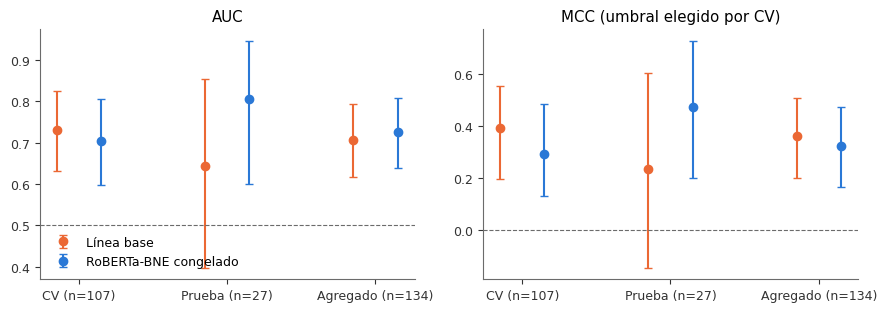

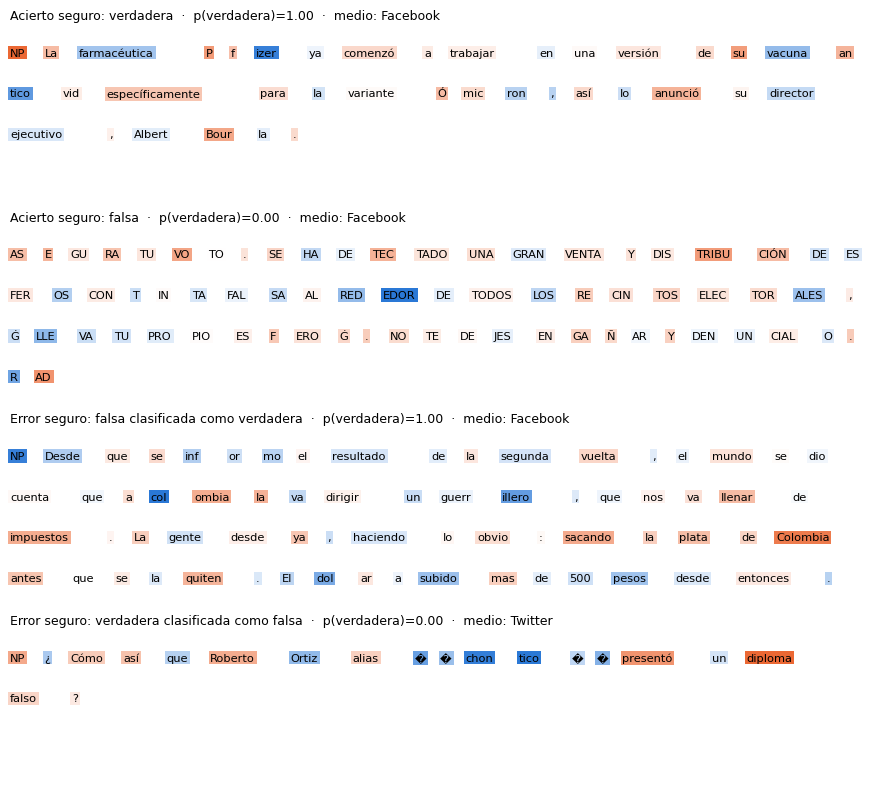

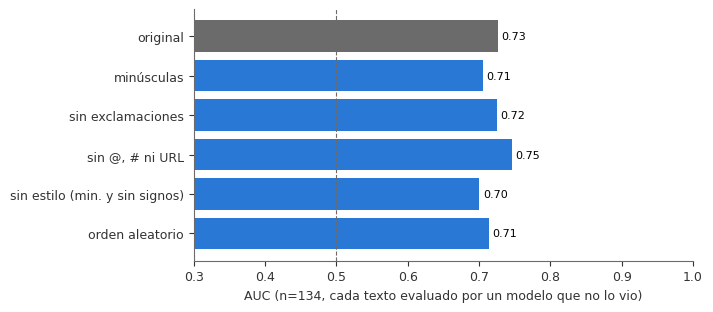

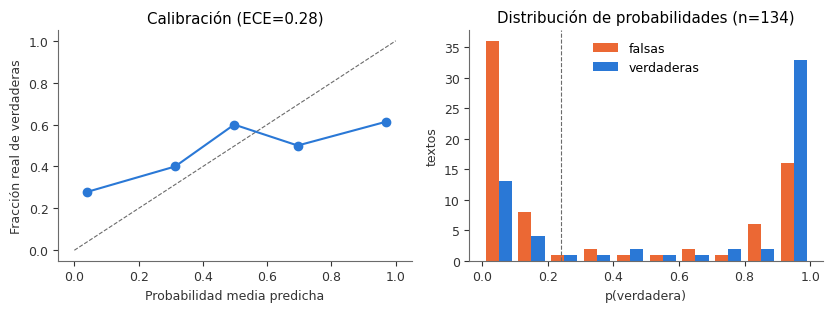

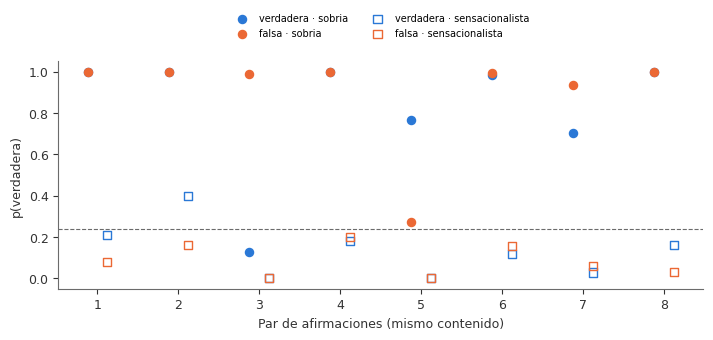

In [11]:
# Celda 11 — Figuras
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY, "axes.labelcolor": "#333", "xtick.color": "#333", "ytick.color": "#333"})
# (1) comparación con intervalos
fig, axs = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, met, ttl in zip(axs, ["auc", "mcc"], ["AUC", "MCC (umbral elegido por CV)"]):
    for j, nm in enumerate(["desarrollo_oof_107", "prueba_27", "agregado_134"]):
        yy, pt, pb = {"desarrollo_oof_107": (y_tr, oof_t, base_oof), "prueba_27": (y_te, te_ens, base_te), "agregado_134": (Y_POOL, T_POOL, B_POOL)}[nm]
        for k, (p, thr, col, lab) in enumerate([(pb, thr_b, ORANGE, "Línea base"), (pt, thr_t, BLUE, "RoBERTa-BNE congelado")]):
            bs = []
            for _ in range(500):
                i = rng.integers(0, len(yy), len(yy))
                if len(set(yy[i])) > 1: bs.append(metr(yy[i], p[i], thr)[met])
            v = metr(yy, p, thr)[met]; x = j + (k - .5) * .3
            ax.errorbar(x, v, yerr=[[v - np.percentile(bs, 2.5)], [np.percentile(bs, 97.5) - v]], fmt="o", color=col, capsize=3, label=lab if j == 0 else None)
    ax.set_xticks(range(3)); ax.set_xticklabels(["CV (n=107)", "Prueba (n=27)", "Agregado (n=134)"]); ax.set_title(ttl)
    ax.axhline(0.5 if met == "auc" else 0, color=GRAY, lw=.8, ls="--")
axs[0].legend(frameon=False, loc="lower left"); plt.tight_layout(); plt.savefig(OUT / "fig_f3_comparacion.png", dpi=170); plt.show(); plt.close()

# (2) saliencia por token en 4 ejemplos de prueba (2 aciertos seguros y 2 errores seguros)
Pt = P[P.conjunto == "prueba"].copy(); Pt["pos"] = [int(np.where(df.index.values == i)[0][0]) for i in Pt.idx]
sel = [("Acierto seguro: verdadera", Pt[(Pt.y == 1) & (Pt.error == 0)].sort_values("prob", ascending=False)),
       ("Acierto seguro: falsa", Pt[(Pt.y == 0) & (Pt.error == 0)].sort_values("prob")),
       ("Error seguro: falsa clasificada como verdadera", Pt[(Pt.y == 0) & (Pt.error == 1)].sort_values("prob", ascending=False)),
       ("Error seguro: verdadera clasificada como falsa", Pt[(Pt.y == 1) & (Pt.error == 1)].sort_values("prob"))]
def blend(v):                       # v en [-1, 1]; azul = empuja a «verdadera», naranja = empuja a «falsa»
    c = np.array(matplotlib.colors.to_rgb(BLUE if v > 0 else ORANGE)); a = min(1, abs(v) ** .7); return tuple(1 - a * (1 - c))
import matplotlib
fig, axs = plt.subplots(4, 1, figsize=(9, 8.2))
for ax, (ttl, d) in zip(axs, sel):
    ax.axis("off")
    if len(d) == 0: ax.set_title(ttl + " (sin casos)", loc="left", fontsize=9); continue
    r = d.iloc[0]; e = EX[int(r.pos)]; m = np.abs(e["sal"]).max() + 1e-12
    ax.set_title(f"{ttl}  ·  p(verdadera)={r.prob:.2f}  ·  medio: {r.medio}", loc="left", fontsize=9)
    x, yv = 0.0, 0.88
    for t, s in list(zip(e["tokens"], e["sal"]))[:70]:
        w = 0.0105 * (len(t) + 1.2) + 0.006
        if x + w > 1: x, yv = 0.0, yv - 0.24
        if yv < 0: break
        ax.text(x, yv, t, fontsize=8.2, bbox=dict(facecolor=blend(s / m), edgecolor="none", pad=1.2), transform=ax.transAxes, va="top"); x += w
plt.tight_layout(); plt.savefig(OUT / "fig_f3_saliencia.png", dpi=170); plt.show(); plt.close()

# (3) perturbaciones
fig, ax = plt.subplots(figsize=(7.2, 3.2)); pd_ = pert_df.iloc[::-1]
ax.barh(pd_.variante, pd_.auc, color=[GRAY if v == "original" else BLUE for v in pd_.variante]); ax.axvline(0.5, color=GRAY, lw=.8, ls="--"); ax.set_xlim(0.3, 1)
for i, v in enumerate(pd_.auc): ax.text(v + .005, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("AUC (n=134, cada texto evaluado por un modelo que no lo vio)"); plt.tight_layout(); plt.savefig(OUT / "fig_f3_perturbaciones.png", dpi=170); plt.show(); plt.close()

# (4) calibración
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2)); e5 = np.linspace(0, 1, 6)
xs, ys = [], []
for i in range(5):
    m = (T_POOL >= e5[i]) & ((T_POOL < e5[i + 1]) if i < 4 else (T_POOL <= 1))
    if m.sum() >= 2: xs.append(T_POOL[m].mean()); ys.append(Y_POOL[m].mean())
axs[0].plot([0, 1], [0, 1], color=GRAY, ls="--", lw=.8); axs[0].plot(xs, ys, "o-", color=BLUE); axs[0].set_xlabel("Probabilidad media predicha"); axs[0].set_ylabel("Fracción real de verdaderas"); axs[0].set_title(f"Calibración (ECE={ece(Y_POOL, T_POOL):.2f})")
axs[1].hist([T_POOL[Y_POOL == 0], T_POOL[Y_POOL == 1]], bins=np.linspace(0, 1, 11), color=[ORANGE, BLUE], label=["falsas", "verdaderas"]); axs[1].axvline(thr_t, color=GRAY, ls="--", lw=.8)
axs[1].set_xlabel("p(verdadera)"); axs[1].set_ylabel("textos"); axs[1].legend(frameon=False); axs[1].set_title("Distribución de probabilidades (n=134)")
plt.tight_layout(); plt.savefig(OUT / "fig_f3_calibracion.png", dpi=170); plt.show(); plt.close()

# (5) casos conocidos
fig, ax = plt.subplots(figsize=(7.2, 3.6)); mk = {"verdadera · sobria": ("o", BLUE, True), "falsa · sobria": ("o", ORANGE, True), "verdadera · sensacionalista": ("s", BLUE, False), "falsa · sensacionalista": ("s", ORANGE, False)}
for t, (m_, c_, fill) in mk.items():
    d = K[K.tipo == t]; ax.scatter(d.par + (0.12 if "sens" in t else -0.12), d.prob, marker=m_, s=34, facecolors=c_ if fill else "none", edgecolors=c_, label=t)
ax.axhline(thr_t, color=GRAY, ls="--", lw=.8); ax.set_xlabel("Par de afirmaciones (mismo contenido)"); ax.set_ylabel("p(verdadera)"); ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper center", bbox_to_anchor=(.5, 1.25))
plt.tight_layout(); plt.savefig(OUT / "fig_f3_casos.png", dpi=170); plt.show(); plt.close()

In [12]:
# Celda 12 — Costo y guardado
cost = dict(base_fit_s=t_base_fit, base_pred_ms_por_texto=t_base_pred * 1000, embed_ms_por_texto=t_embed * 1000, cabezal_fit_s=t_head_fit, cv_grid_s=t_cv, explain_ms_por_texto=t_expl * 1000,
            params_encoder=int(sum(p.numel() for p in enc.parameters())), params_cabezal=int(sum(p.numel() for p in final_heads[0]["head"].parameters())),
            vocab_tfidf=len(base.named_steps["tfidf"].vocabulary_))
print(cost)
jd = lambda o: o.item() if hasattr(o, "item") else str(o)
res = dict(entorno=ENV, model_id=MODEL_ID, config=dict(MAX_LEN=MAX_LEN, BATCH=BATCH, WEIGHT_DECAY=WEIGHT_DECAY, DROPOUT=DROPOUT, GRID=GRID, CV_SEEDS=CV_SEEDS, FINAL_SEEDS=FINAL_SEEDS, N_BOOT=N_BOOT),
           grid_cv=grid_table.to_dict("records"), elegida=BEST, umbral_transformer=thr_t, umbral_base=thr_b, lr_sobre_embeddings_cv_auc=float(roc_auc_score(y_tr, lr_oof)),
           prueba_por_semilla=dict(f1=sd("f1"), mcc=sd("mcc"), auc=sd("auc")), trivial_todo_verdadera=triv, comparacion=comp,
           saliencia=dict(enriquecimiento=enrich.to_dict("records"), tokens_hacia_falsa=top_falsa.reset_index().to_dict("records"), tokens_hacia_verdadera=top_verd.reset_index().to_dict("records"),
                          spearman_saliencia_atencion=float(rho), spearman_saliencia_rollout=float(rho_r)),
           fallas=fail, errores_fp=int(fp), errores_fn=int(fn), peores_errores=worst.to_dict("records"),
           perturbaciones=pert_df.to_dict("records"), asociacion=assoc, auc_dentro_de_subgrupos=within.to_dict("records"), techo_atajo_solo_metadatos=meta_auc,
           casos_conocidos=known, fuera_de_dominio=ood.to_dict("records"), confianza_media_prueba=float(np.maximum(te_ens, 1 - te_ens).mean()), costo=cost,
           tiempo_total_min=(time.time() - T0) / 60)
(OUT / "explicaciones_tokens.json").write_text(json.dumps([dict(i=i, y=int(y_all[i]), tokens=e["tokens"], saliencia=[round(float(v), 5) for v in e["sal"]], atencion=[round(float(v), 5) for v in e["att_last"]]) for i, e in enumerate(EX)], ensure_ascii=False))
(OUT / "resultados_fase3.json").write_text(json.dumps(res, ensure_ascii=False, indent=1, default=jd))
grid_table.to_csv(OUT / "tabla_grid_cv.csv", index=False); pert_df.to_csv(OUT / "tabla_perturbaciones.csv", index=False); enrich.to_csv(OUT / "tabla_saliencia_categorias.csv", index=False)
shutil.make_archive("resultados_fase3", "zip", OUT); print("Guardado:", sorted(p.name for p in OUT.iterdir())); print(f"Tiempo total: {(time.time()-T0)/60:.1f} min")
try:
    from google.colab import files; files.download("resultados_fase3.zip")
except ImportError:
    pass

{'base_fit_s': 0.11227383900001087, 'base_pred_ms_por_texto': 0.4660985555557528, 'embed_ms_por_texto': 12.221747559701539, 'cabezal_fit_s': 0.9713060233999954, 'cv_grid_s': 86.43840672900001, 'explain_ms_por_texto': 37.09393689552205, 'params_encoder': 124643328, 'params_cabezal': 592130, 'vocab_tfidf': 1282}
Guardado: ['casos_respuesta_conocida.csv', 'explicaciones_tokens.json', 'fig_f3_calibracion.png', 'fig_f3_casos.png', 'fig_f3_comparacion.png', 'fig_f3_perturbaciones.png', 'fig_f3_saliencia.png', 'predicciones_fuera_de_muestra_134.csv', 'resultados_fase3.json', 'tabla_grid_cv.csv', 'tabla_perturbaciones.csv', 'tabla_saliencia_categorias.csv']
Tiempo total: 6.5 min
